\newcounter{none}
\setcounter{secnumdepth}{0}

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft

from student_seed import get_my_params

params = get_my_params("2011-06521")
rng = params["rng"]

# Signal Generation

## Define and sample the signal

We can define the analog signal $x_1(t)$ as follows:

$$
x_1(t)=
\begin{cases}
-\frac{A}{2}, & t < -2 \\
\frac{A}{2}, & -2 \le t < -1 \\
A-\frac{A}{2}t, & -1 \le t < 0 \\
A, & 0 \le t < 1 \\
A(2-t), & 1 \le t < 2 \\
-\frac{A}{2}, & t \ge 2
\end{cases}
$$

which we represent in Python using `np.select`


In [2]:
A = 2
samp_freq = 10

t_start = -2.5
t_end = 2.5

# define analog signal
def x1(t):
    t = np.asarray(t, dtype=np.float64)

    return np.select(
        [
            t < -2,
            (t >= -2) & (t < -1),
            (t >= -1) & (t < 0),
            (t >= 0) & (t < 1),
            (t >= 1) & (t < 2),
            t >= 2,
        ],
        [
            -A / 2,
            A / 2,
            A - ((A / 2) * t),
            A,
            A * (2 - t),
            -A / 2,
        ],
    )


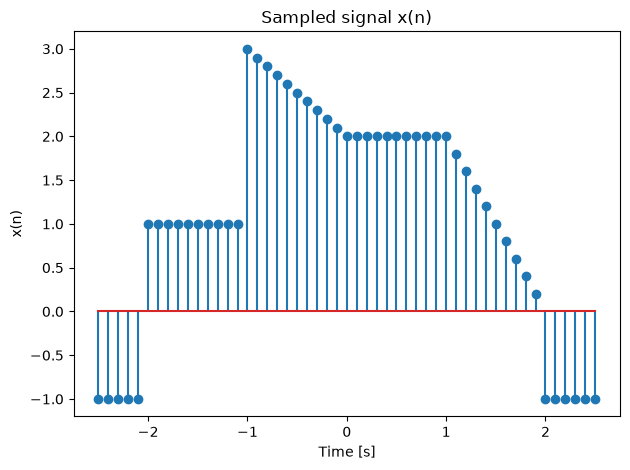

At t = -0.5, x1(t) =  2.5


In [3]:
# sampling
n = np.arange(t_start * samp_freq, t_end * samp_freq + 1) / samp_freq
x = x1(n)

plt.stem(n, x)
plt.xlabel("Time [s]")
plt.ylabel("x(n)")
plt.title("Sampled signal x(n)")
plt.tight_layout()
plt.show()

print("At t = -0.5, x1(t) = ", x1(-0.5))

To confirm:

$x_1(-0.5) = A - \frac{A}{2}t = 2 - \frac{2}{2}(-0.5) = 2.5$

## Even–odd decomposition

To get the even and odd components of the signal, we can use the following formulas:

$x_e(n) = \frac{x_1(n) + x_1(-n)}{2}$

$x_o(n) = \frac{x_1(n) - x_1(-n)}{2}$


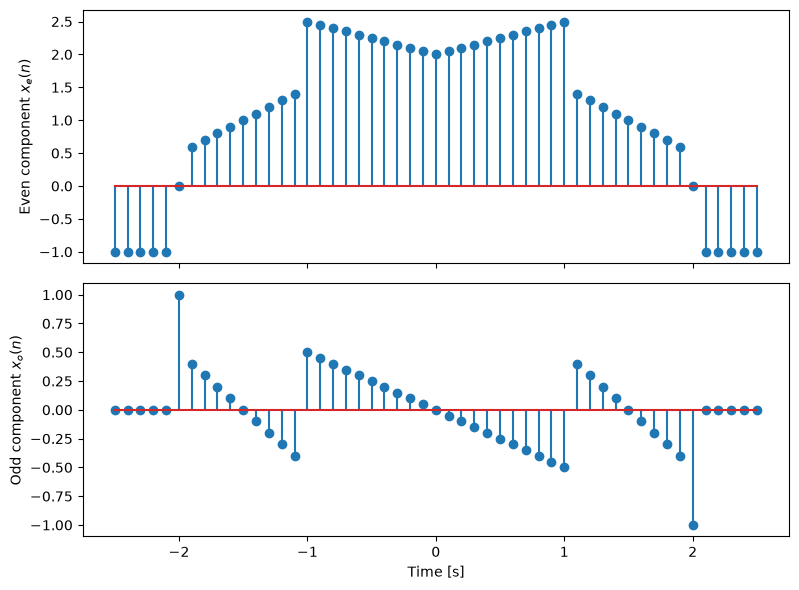

In [4]:
x_neg = x1(-n)
x_e = (x + x_neg) / 2
x_o = (x - x_neg) / 2

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
ax[0].stem(n, x_e)
ax[0].set_ylabel("Even component $x_e(n)$")
ax[1].stem(n, x_o)
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel("Odd component $x_o(n)$")

plt.tight_layout()
plt.show()


## Verify the decomposition

To confirm that the decomposed components are correct, confirm that $x_1(n) = x_e(n) + x_o(n)$ for all $n$.

In [5]:
np.allclose(x, x_e + x_o)

True

# Discrete-Time System Representations

## Derive the system transfer function

The difference equation for the system is represented by both the autoregressive parts (left adder, $w[n]$)

$$
w[n] = x[n] + 4w[n-1] - w[n-2]
$$

and the moving average parts (right adder, $y[n]$)

$$
y[n] = 2w[n] - 5w[n-1] - 3w[n-2]
$$

Transforming the equations to the z-transform, we'll get:

$$
\begin{aligned}
W(z) = X(z) + 4z^{-1}W(z) - z^{-2}W(z)\\
(1 - 4z^{-1} + z^{-2})W(z) = X(z)\\
W(z) = \frac{X(z)}{(1 - 4z^{-1} + z^{-2})}
\end{aligned}
$$

$$
\begin{aligned}
Y(z) = 2W(z) - 5z^{-1}W(z) - 3z^{-2}W(z)\\
Y(z) = (2 - 5z^{-1} - 3z^{-2})W(z)\\
\end{aligned}
$$

now we'll eliminate $W(z)$ from the two equations so we can get the system's input-output equation in the z-domain:

$$
\begin{aligned}
Y(z) = \frac{(2 - 5z^{-1} - 3z^{-2})}{(1 - 4z^{-1} + z^{-2})} X(z)\\
(1 - 4z^{-1} + z^{-2})Y(z) = (2 - 5z^{-1} - 3z^{-2})X(z)
\end{aligned}
$$

converting back to the time domain, we can express the system as a difference equation:

$$
\begin{aligned}
y[n] - 4y[n-1] + y[n-2] = 2x[n] - 5x[n-1] - 3x[n-2]\\
y[n] = 4y[n-1] - y[n-2] + 2x[n] - 5x[n-1] - 3x[n-2]
\end{aligned}
$$

to get the coefficients, we can express the system in terms of the coefficients of the difference equation:

$$
\begin{aligned}
y[n] = -\sum_{k=1}^{2}a_k y[n-k] + \sum_{k=0}^{2}b_k x[n-k], a_0 = 1\\
y[n] = -(-4y[n-1] + y[n-2]) + (2x[n] - 5x[n-1] - 3x[n-2])
\end{aligned}
$$

and we can conclude that $a_0 = 1, a_1 = -4, a_2 = 1, b_0 = 2, b_1 = -5, b_2 = -3$.

## Test BIBO stability by recursion

To test if the system is BIBO stable using recursion, we use a bounded input (in our case, a unit step function) and check if the output produced is bounded as well.

An output is bounded if there is some fixed number $M$ where:

$$
|y[n]| < M
$$

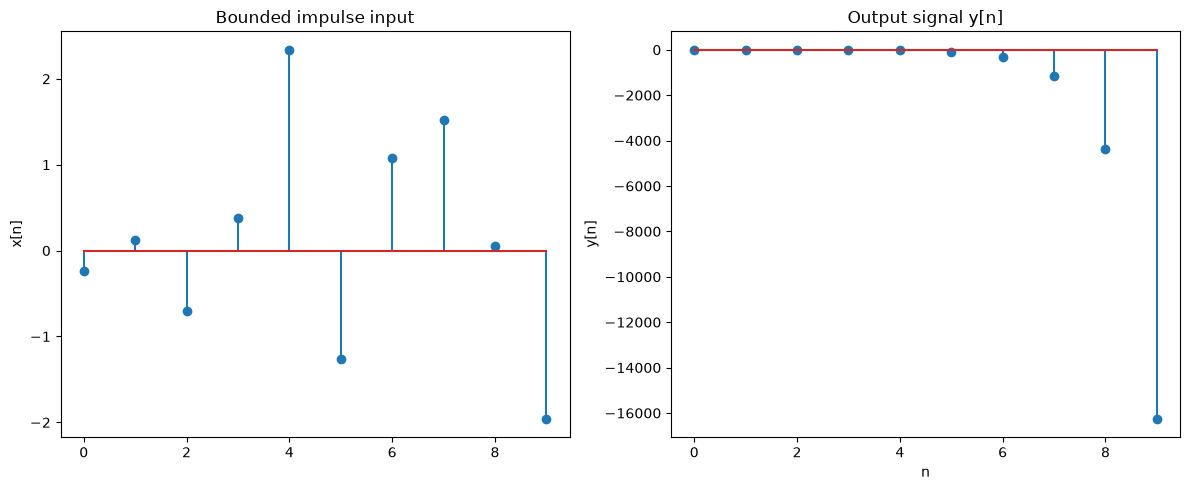

Given that at n = 9, y[n] =  -16242.58741383137 we can conclude that the output is not bounded and the system is not BIBO stable.


In [6]:
def y_func(x, a, b, N):
  y = np.zeros(N)

  for n in range(N):
    feedforward = sum(b[k] * x[n - k] for k in range(len(b)) if n - k >= 0)
    feedback = sum(a[k] * y[n - k] for k in range(1, len(a)) if n - k >= 0)

    y[n] = -feedback + feedforward

  return y

####

a = np.array([1, -4, 1])
b = np.array([2, -5, -3])

N = 10 # sample size

x = rng.normal(size=N)

y = y_func(x, a, b, N)
n = np.arange(N)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

ax[0].stem(n, x)
ax[0].set_ylabel("x[n]")
ax[0].set_title("Bounded impulse input")

ax[1].stem(n, y)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y[n]")
ax[1].set_title("Output signal y[n]")

plt.tight_layout()
plt.show()

print("Given that at n = 9, y[n] = ", y[9], "we can conclude that the output is not bounded and the system is not BIBO stable.")

## Compare impulse-response implementations

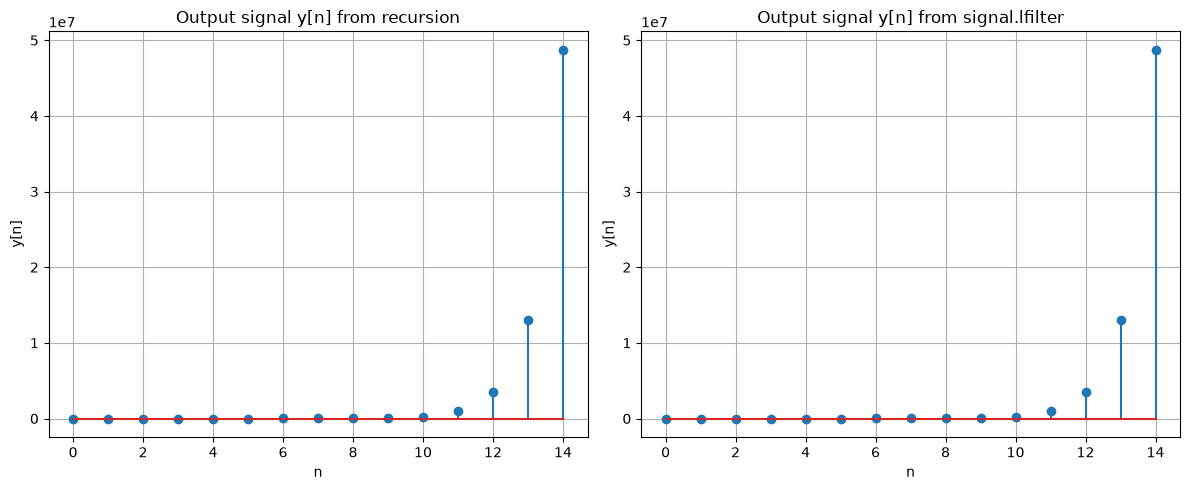

The output is still not bounded, proving that the system is not BIBO stable.


In [7]:
N = 15
x_impulse = np.zeros(N)
x_impulse[0] = 1

y_impulse = y_func(x_impulse, a, b, N)
y_signal = signal.lfilter(b, a, x_impulse)
n = np.arange(N)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

ax[0].stem(n, y_impulse)
ax[0].set_xlabel("n")
ax[0].set_ylabel("y[n]")
ax[0].set_title("Output signal y[n] from recursion")
ax[0].grid()

ax[1].stem(n, y_signal)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y[n]")
ax[1].set_title("Output signal y[n] from signal.lfilter")
ax[1].grid()

plt.tight_layout()
plt.show()

print("The output is still not bounded, proving that the system is not BIBO stable.")

## Inspect the pole-zero plot

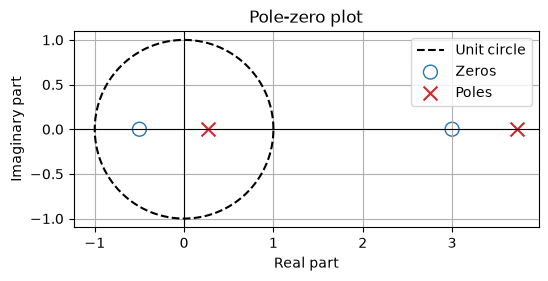

Zeros: [ 3.  -0.5]
Poles: [3.73205081 0.26794919]


In [8]:
zeros, poles, gain = signal.tf2zpk(b, a)

theta = np.linspace(0, 2 * np.pi, 500)

fig, ax = plt.subplots(figsize=(6, 6))

# unit circle
ax.plot(np.cos(theta), np.sin(theta), "k--", label="Unit circle")

# zeros and poles
ax.scatter(zeros.real, zeros.imag, marker="o",
           facecolors="none", edgecolors="tab:blue",
           s=100, label="Zeros")

ax.scatter(poles.real, poles.imag, marker="x",
           color="tab:red", s=100, label="Poles")

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_aspect("equal")
ax.set_xlabel("Real part")
ax.set_ylabel("Imaginary part")
ax.set_title("Pole-zero plot")
ax.legend()
ax.grid()
plt.show()

print("Zeros:", zeros)
print("Poles:", poles)

Given that a pole is outside the unit circle $|z| = 1$, we can confirm the system is not BIBO stable.


Now, recreating this with a perturbed denominator coefficient:

## Analyze the perturbed system

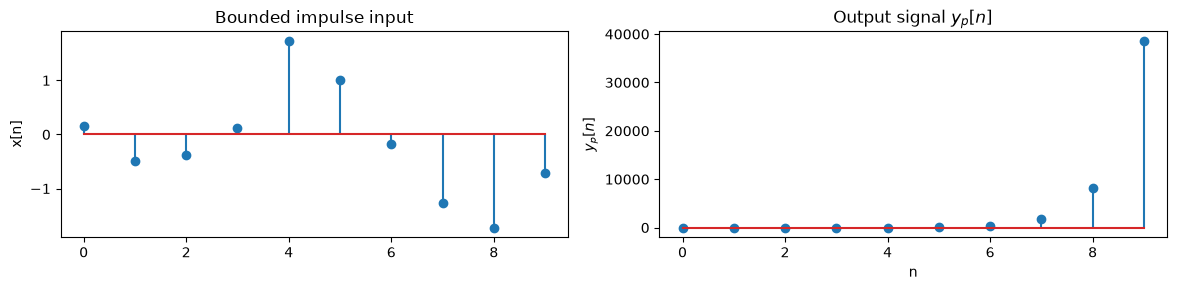

Given that at n = 9, y[n] =  -16242.58741383137 we can conclude that the output is not bounded and the system is not BIBO stable.


In [9]:
p = (1 + params["offset_small"] / 100)

a_p = np.array([1, -4 * p, 1])
b = np.array([2, -5, -3])

N = 10 # sample size

x = rng.normal(size=N)

y_p = y_func(x, a_p, b, N)
n = np.arange(N)

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharex=True)

ax[0].stem(n, x)
ax[0].set_ylabel("x[n]")
ax[0].set_title("Bounded impulse input")

ax[1].stem(n, y_p)
ax[1].set_xlabel("n")
ax[1].set_ylabel("$y_p[n]$")
ax[1].set_title("Output signal $y_p[n]$")

plt.tight_layout()
plt.show()

print("Given that at n = 9, y[n] = ", y[9], "we can conclude that the output is not bounded and the system is not BIBO stable.")



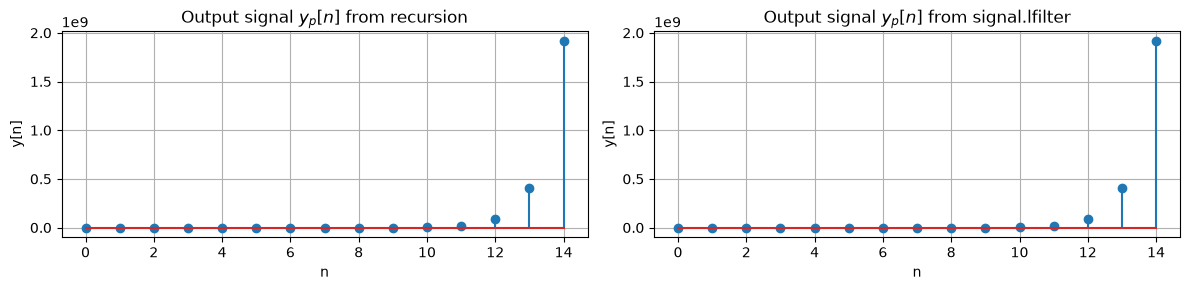

The output is still not bounded, proving that the system is not BIBO stable.


In [10]:
N = 15
x_impulse = np.zeros(N)
x_impulse[0] = 1

y_impulse_p = y_func(x_impulse, a_p, b, N)
y_signal_p = signal.lfilter(b, a_p, x_impulse)
n = np.arange(N)

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharex=True)

ax[0].stem(n, y_impulse_p)
ax[0].set_xlabel("n")
ax[0].set_ylabel("y[n]")
ax[0].set_title("Output signal $y_p[n]$ from recursion")
ax[0].grid()

ax[1].stem(n, y_signal_p)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y[n]")
ax[1].set_title("Output signal $y_p[n]$ from signal.lfilter")
ax[1].grid()

plt.tight_layout()
plt.show()

print("The output is still not bounded, proving that the system is not BIBO stable.")

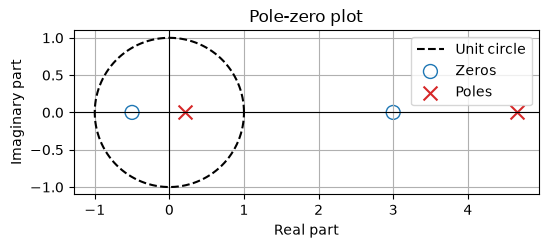

Zeros: [ 3.  -0.5]
Poles: [4.66566844 0.21433156]


In [11]:
zeros, poles, gain = signal.tf2zpk(b, a_p)

theta = np.linspace(0, 2 * np.pi, 500)

fig, ax = plt.subplots(figsize=(6, 6))

# unit circle
ax.plot(np.cos(theta), np.sin(theta), "k--", label="Unit circle")

# zeros and poles
ax.scatter(zeros.real, zeros.imag, marker="o",
           facecolors="none", edgecolors="tab:blue",
           s=100, label="Zeros")

ax.scatter(poles.real, poles.imag, marker="x",
           color="tab:red", s=100, label="Poles")

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_aspect("equal")
ax.set_xlabel("Real part")
ax.set_ylabel("Imaginary part")
ax.set_title("Pole-zero plot")
ax.legend()
ax.grid()
plt.show()

print("Zeros:", zeros)
print("Poles:", poles)

Even with the perturbed coefficient, there are still zeros and poles outside the unit circle, maintaining that the system is not BIBO stable.

# Signal synthesis using Fourier analysis



## Create the input signal

Start by creating the original input signal.

In [12]:
Fs = 200
T = 1
N = Fs * T

n = np.arange(N)
t = n / Fs

x = np.select(
  [
    (t < 0.25) | (t > 0.75),
    ((t >= 0.25) & (t < 0.375)) | ((t >= 0.625) & (t < 0.75)),
    (t >= 0.375) & (t < 0.625),
  ],
  [0.0, 0.5, 1.0],
)

## Compute Fourier coefficients

Now compute for the Fourier coefficients using the formula:

$$
c_{k} = \frac{1}{N}\sum_{n=0}^{N-1} x(n)e^{-j2\pi kn / N}
$$

We can also use `scipy.fft` to compute these coefficients

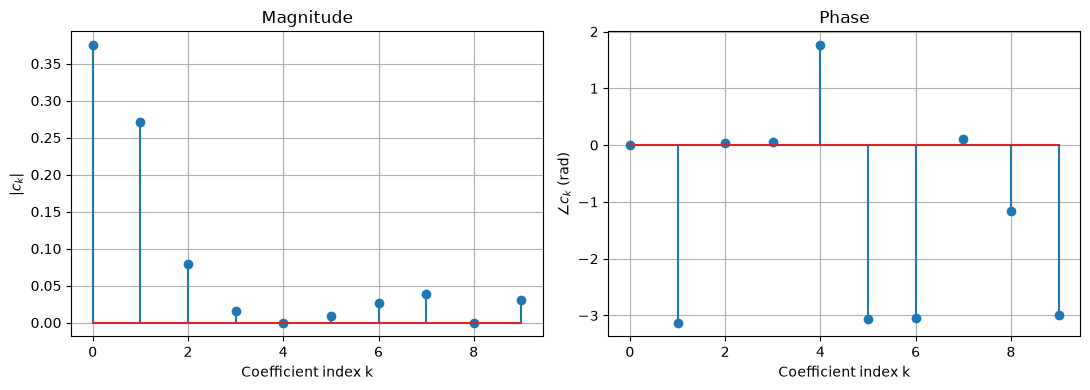

In [13]:
# Manual computation
# c = np.zeros(N, dtype=complex)

# for k in range(N):
#   c[k] = (1/N) * np.sum(x * np.exp(-1j * 2 * np.pi * k * n / N))

c = fft.fft(x) / N  # pyright: ignore[reportOperatorIssue]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

magnitude_10 = np.abs(c[:10])  # pyright: ignore[reportCallIssue, reportArgumentType]
ax[0].stem(magnitude_10)
ax[0].set_title("Magnitude")
ax[0].set_xlabel("Coefficient index k")
ax[0].set_ylabel(r"$|c_k|$")
ax[0].grid(True)

phase_10 = np.angle(c[:10])  # pyright: ignore[reportCallIssue, reportArgumentType]
ax[1].stem(phase_10)
ax[1].set_title("Phase")
ax[1].set_xlabel("Coefficient index k")
ax[1].set_ylabel(r"$\angle c_k$ (rad)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

## Reconstruct the signal

Now to recreate the input signal we can use the following:

$$
x_{rec}(n) = \sum_{k=0}^{N-1}c_k\exp^{j2\pi kn/N}
$$

or we can use `scipy.ifft` to do the inverse transform and recreate the signal using the coefficients.

/Users/carldegs/Documents/upd/ai-321/me-01/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/carldegs/Documents/upd/ai-321/me-01/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


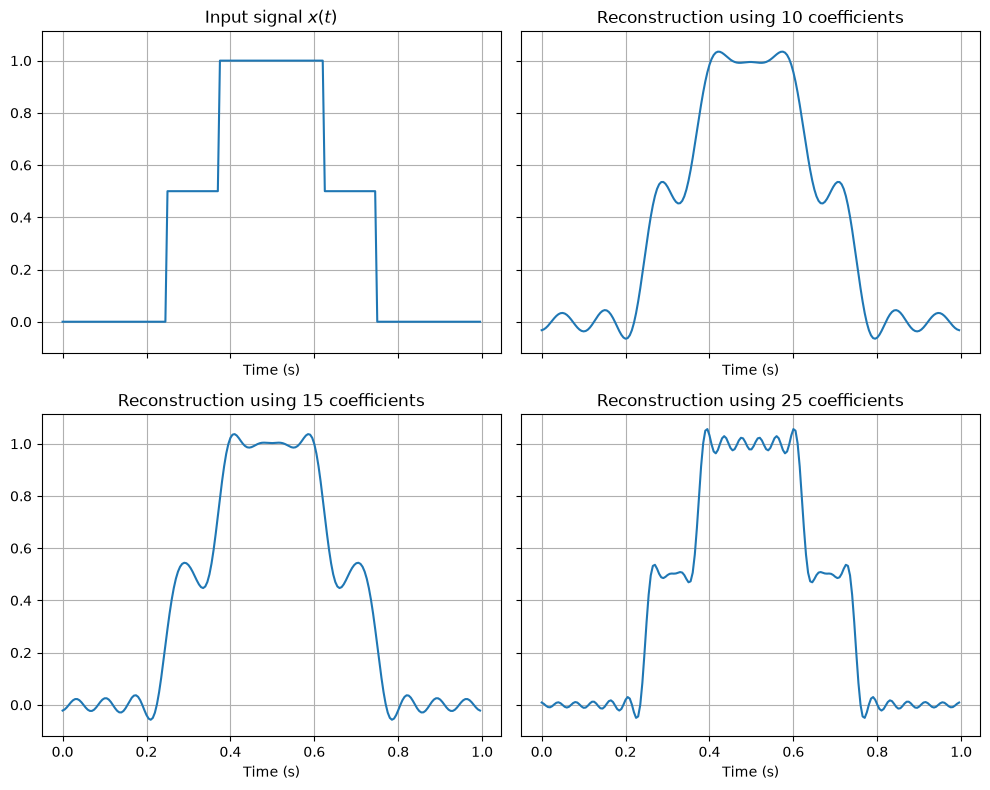

In [14]:
def reconstruct(M, coefficients=c.copy()):
    # Keep c[0] through c[M-1] plus the matching negative-frequency bins.
    num_samples = coefficients.size
    max_coefficients = num_samples // 2 + 1
    if not 1 <= M <= max_coefficients:
        raise ValueError(f"M must be between 1 and {max_coefficients}")

    indices = np.concatenate((
        np.arange(M),           # 0, 1, ..., M-1
        num_samples - np.arange(1, M)
    ))

    c_rec = np.zeros_like(coefficients)
    c_rec[indices] = coefficients[indices]

    return num_samples * fft.ifft(c_rec)  # pyright: ignore[reportOperatorIssue]

x_10 = reconstruct(10)
x_15 = reconstruct(15)
x_25 = reconstruct(25)

fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

plots = [
    (x, "Input signal $x(t)$"),
    (x_10, "Reconstruction using 10 coefficients"),
    (x_15, "Reconstruction using 15 coefficients"),
    (x_25, "Reconstruction using 25 coefficients"),
]

for axis, (signal_to_plot, title) in zip(ax.flat, plots):
    axis.plot(t, signal_to_plot)
    axis.set_title(title)
    axis.set_xlabel("Time (s)")
    axis.grid(True)

plt.tight_layout()
plt.show()

## Explore reconstruction interactively

To play around with this, I've used `ipywidgets` to set a slider to change the coefficients used in reconstruction and plot the output.

We can observe that as the number of coefficients used are increased, the reconstructed signal resembles the original signal more closely. The transition points are more accurate and the flat regions are more accurate, though oscillation increases.

In [15]:
from io import BytesIO

import ipywidgets as widgets
from IPython.display import Image, display

time = t.copy()
signal_samples = x.copy()

slider = widgets.IntSlider(
    value=10,
    min=1,
    max=c.size // 2 + 1,
    step=1,
    description="Coefficients:",
    continuous_update=True,
    style={"description_width": "initial"},
)

def plot_reconstruction(M):
    x_rec = reconstruct(M)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.step(time, signal_samples, where="post", color="tab:blue",
             linewidth=1, label="Original signal")
    ax.plot(time, x_rec, color="tab:red",
             label=f"Reconstruction: {M} coefficients")

    ax.set_title(f"Fourier reconstruction using {M} coefficients")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-0.3, 1.3)
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    image_buffer = BytesIO()
    fig.savefig(image_buffer, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(data=image_buffer.getvalue()))

output = widgets.interactive_output(plot_reconstruction, {"M": slider})
display(widgets.VBox([slider, output]))

# Frequency analysis of signals

## Create the composite sinusoidal signal

First we'll create the signal $x_s(t)$

## Compute the one-sided DFT

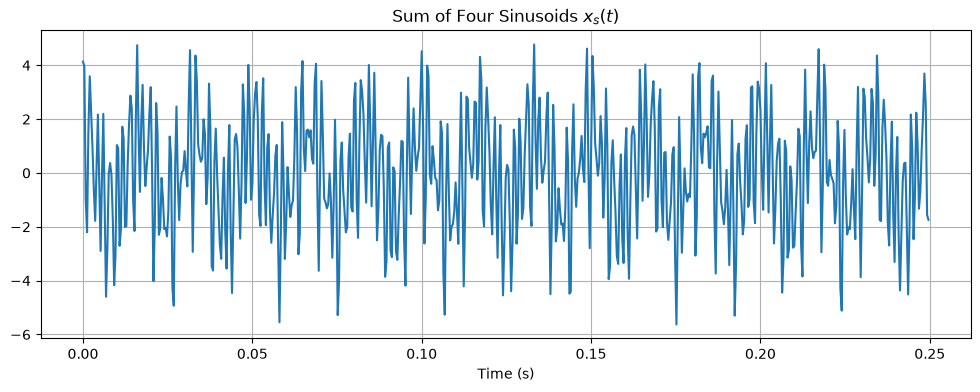

In [24]:
Fs = 2500
T = 0.25
Nfft = 512

t = np.arange(0, T, 1/Fs)

def get_xs(t):
  x1 = 1.5 * np.cos(120 * np.pi * t)
  x2 = 1.0 * np.sin((700 * np.pi * t) + np.deg2rad(150)) # numpy's sin and cos expects radians as input
  x3 = 1.3 * np.sin((1400 * np.pi * t) + np.deg2rad(30))
  x4 = 2.1 * np.cos((1024 * np.pi * t) - np.deg2rad(45))

  return x1 + x2 + x3 + x4

xs = get_xs(t)

plt.figure(figsize=(12, 4))
plt.plot(t, xs)
plt.xlabel("Time (s)")
plt.title("Sum of Four Sinusoids $x_s(t)$")
plt.grid(True)
plt.show()

Then we'll compute and plot the one-sided discrete Fourier transform using $Nfft = 512$.

This is done by doing the FFT and only getting the results from the positive frequencies $0$ to $F_s / 2$. We do this by using `fft.rfft` which does exactly this instead of `fft.fft` which returns all Nfft bins on both the positive and negative frequencies.

To verify if the computation is correct, we need to confirm the peaks are shown at each signal's frequencies.

Given the input sinusoidal signals $A\sin{(\omega t + \theta)}$ or $A\cos{(\omega t + \theta)}$, we can get the signal's frequency:

$$
\begin{aligned}
\omega = 2\pi f \\
f = \frac{\omega}{2\pi}
\end{aligned}
$$

Therefore the input signal's frequencies are:

$$
f_1 = \frac{120\pi}{2\pi} = 60 Hz
$$

$$
f_2 = \frac{700\pi}{2\pi} = 350 Hz
$$

$$
f_3 = \frac{1400\pi}{2\pi} = 700 Hz
$$

$$
f_4 = \frac{1024\pi}{2\pi} = 512 Hz
$$


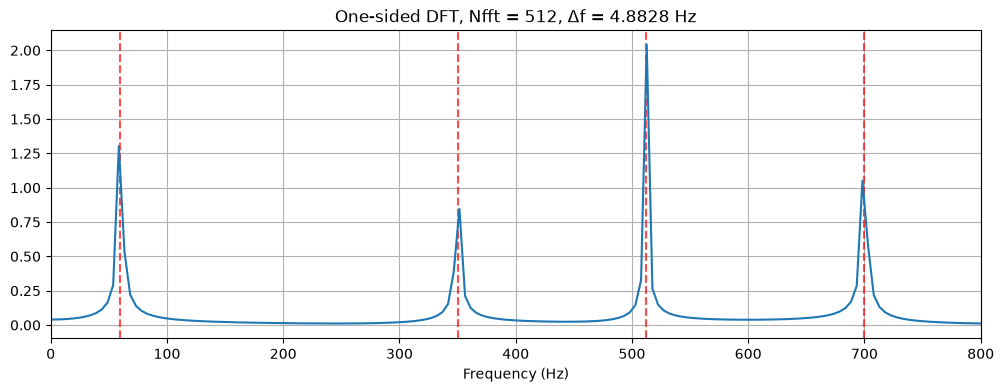

In [17]:
# Instead of using fft.fft which returns all Nfft bins on both positive and negative frequencies,
# we use fft.rfft instead which only returns unique bins from 0 to Fs / 2 (Nfft // 2 + 1)
Xs = fft.rfft(xs, Nfft)

# We only want the one-sided frequency axis
f = np.fft.rfftfreq(Nfft, 1/Fs)
mag = np.abs(Xs) / Nfft * 2  # pyright: ignore[reportCallIssue, reportArgumentType, reportOperatorIssue]

expected_freqs = [60, 350, 700, 512]

# Get the frequency resolution
df = Fs / Nfft

plt.figure(figsize=(12, 4))

for freq in expected_freqs:
    plt.axvline(
        x=freq,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"{freq} Hz"
    )

plt.plot(f, mag)
plt.xlabel("Frequency (Hz)")
plt.xlim(0, 800)
plt.title(f"One-sided DFT, Nfft = {Nfft}, Δf = {df:.4f} Hz")
plt.grid(True)
plt.show()

## Identify FFT peaks and frequency error

Now, to get the frequency resolution $\Delta f$:

$$
\begin{aligned}
\Delta f = \frac{F_s}{N_{fft}}\\
\Delta f = \frac{2500 Hz}{512} = 4.8828 Hz
\end{aligned}
$$

Even though the graph shows the peaks matching the input frequencies, in reality the peaks are shown at slightly different frequencies. This is due to the input frequencies not falling exactly on a bin which is $\Delta f = 4.8828 Hz$ wide, so their energy spreads between nearby bins.

To show the discrepancy, we'll use `scipy.signal.find_peaks` to get the peaks' magnitudes and frequencies.

In [18]:
import pandas as pd

def get_peaks(mag, f, df, expected_freqs):
    peaks, _ = signal.find_peaks(
        mag,
        prominence=0.1,
        distance=int(40 / df)
    )

    # Keep the four strongest peaks
    top4 = peaks[np.argsort(mag[peaks])[-4:]]

    # Sort those peaks from lowest to highest frequency
    top4 = top4[np.argsort(f[top4])]

    expected_sorted = np.sort(expected_freqs)

    results = pd.DataFrame({
        "Expected frequency (Hz)": expected_sorted,
        "FFT peak frequency (Hz)": f[top4],
        "Discrepancy (Hz)": abs(f[top4] - expected_sorted),
        "Peak magnitude": mag[top4]
    })

    results.index += 1
    results.index.name = "Signal"

    return results


results = get_peaks(mag, f, df, expected_freqs)
display(results.round(4))

,Expected frequency (Hz),FFT peak frequency (Hz),Discrepancy (Hz),Peak magnitude
Signal,,,,
1,60,58.5938,1.4062,1.3019
2,350,351.5625,1.5625,0.8468
3,512,512.6953,0.6953,2.0424
4,700,698.2422,1.7578,1.0512


## Improve frequency resolution

Now changing the duration $T = 0.5s$ and $N_{fft} = 1024$, the frequency resolution should now be:

$$
\Delta f = \frac{2500 Hz}{1024} = 2.4414 Hz
$$

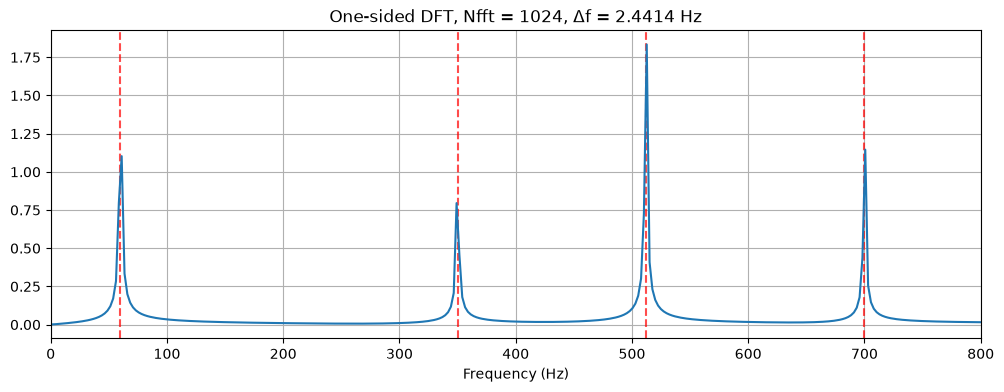

,Expected frequency (Hz),Peak at Δf₁ = 4.8828 Hz,Peak at Δf₂ = 2.4414 Hz,Error at Δf₁ (Hz),Error at Δf₂ (Hz)
Signal,,,,,
1,60,58.5938,61.0352,1.4062,1.0352
2,350,351.5625,349.1211,1.5625,0.8789
3,512,512.6953,512.6953,0.6953,0.6953
4,700,698.2422,700.6836,1.7578,0.6836


In [19]:
T = 0.5
Nfft = 1024

t = np.arange(0, T, 1/Fs)

xs = get_xs(t)
Xs = fft.rfft(xs, Nfft)
f = np.fft.rfftfreq(Nfft, 1/Fs)
mag = np.abs(Xs) / Nfft * 2  # pyright: ignore[reportCallIssue, reportArgumentType, reportOperatorIssue]
expected_freqs = [60, 350, 700, 512]

# Get the frequency resolution
df = Fs / Nfft

plt.figure(figsize=(12, 4))

for freq in expected_freqs:
    plt.axvline(
        x=freq,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"{freq} Hz"
    )

plt.plot(f, mag)
plt.xlabel("Frequency (Hz)")
plt.xlim(0, 800)
plt.title(f"One-sided DFT, Nfft = {Nfft}, Δf = {df:.4f} Hz")
plt.grid(True)
plt.show()

results_2 = get_peaks(mag, f, df, expected_freqs)

comparison = pd.DataFrame({
    "Expected frequency (Hz)": results["Expected frequency (Hz)"].to_numpy(),
    "Peak at Δf₁ = 4.8828 Hz": results["FFT peak frequency (Hz)"].to_numpy(),
    "Peak at Δf₂ = 2.4414 Hz": results_2["FFT peak frequency (Hz)"].to_numpy(),
})

comparison["Error at Δf₁ (Hz)"] = np.abs(
    comparison["Peak at Δf₁ = 4.8828 Hz"]
    - comparison["Expected frequency (Hz)"]
)

comparison["Error at Δf₂ (Hz)"] = np.abs(
    comparison["Peak at Δf₂ = 2.4414 Hz"]
    - comparison["Expected frequency (Hz)"]
)

comparison.index += 1
comparison.index.name = "Signal"

display(comparison.round(4))

From the table above, we can see that the error for most frequencies are reduced when the frequency resolution decreased. For example, the first signal has a discrepancy of $1.4062 Hz$ when $\Delta f = 4.8828Hz$ but only a $1.0352 Hz$ discrepancy when $\Delta f = 2.4414 Hz$

# Random Process

## Generate white-noise realizations

First we'll generate and plot the sample functions of $x(t)$

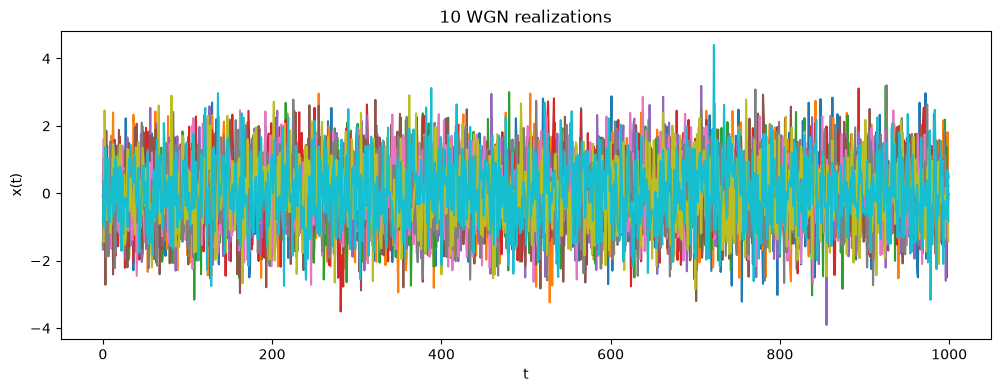

In [20]:
N = 1000
K = 10
X = rng.normal(size=(N, K))

plt.figure(figsize=(12, 4))
plt.plot(np.arange(N), X)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(f"{K} WGN realizations")
plt.show()

## Compare ensemble and time averages

We then get both the ensemble average (average of all realizations given a time t) and the time average (average for each realization).


We can say that a process is stationary if the ensemble average fluctuates around 0, which is evident in the graph below.

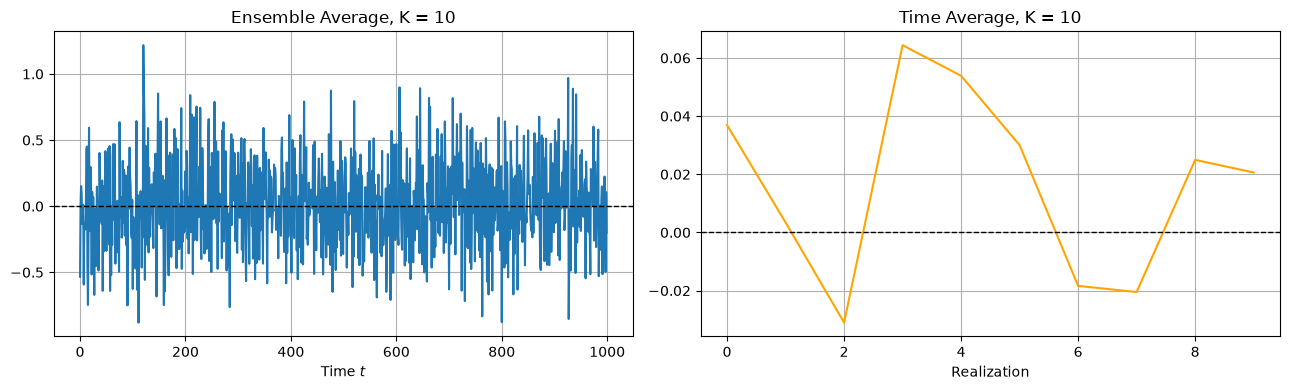

In [21]:
ensemble_avg = X.mean(axis=1) 
time_avg = X.mean(axis=0)

t = np.arange(X.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(t, ensemble_avg)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Ensemble Average, K = 10")
axes[0].set_xlabel("Time $t$")
axes[0].grid(True)

axes[1].plot(time_avg, color="orange")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Average, K = 10")
axes[1].set_xlabel(r"Realization")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Evaluate ergodicity with more realizations

A process is said to be ergodic if its time average converges around a constant even as the realization N increases. Given the graph below, we can see that the time average at K = 1000 is converging around 0, which confirms the process is ergodic.

Comparing this with the ensemble average should show that both of them converges at 0, still confirming that the process is both stationary and ergodic.

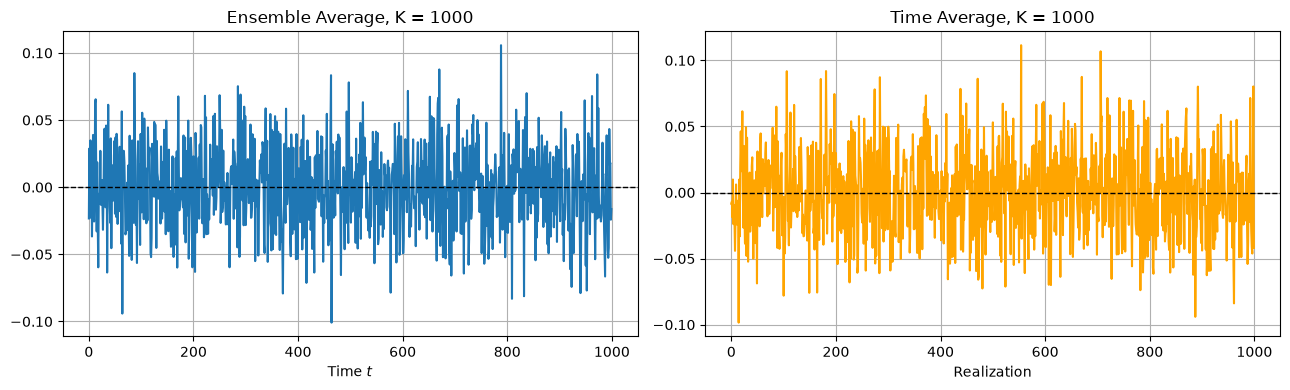

In [22]:
N = 1000
K = 1000
X = rng.normal(size=(N, K))

ensemble_avg = X.mean(axis=1) 
time_avg = X.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(t, ensemble_avg)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Ensemble Average, K = 1000")
axes[0].set_xlabel("Time $t$")
axes[0].grid(True)

axes[1].plot(time_avg, color="orange")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Average, K = 1000")
axes[1].set_xlabel(r"Realization")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Analyze the non-stationary process

For the last item, given the process:

$$
x(t) = 2\sin{(2\pi \cdot 0.002t)} + N_t
$$

we were able to compute both the ensemble mean $\eta _t$ and the time average $\eta (\rho _i)$ for $t = 0, 1, ..., 999$ and $i = 0, 1, ..., 999$

Just by looking at the graph of $\eta _t$, we can see that it is not constant over time therefore it's non-stationary. As further proof, we can compute it's expectation $E[x(t)]$:

$$
\begin{aligned}
E[x(t)] = E[2\sin{(2\pi \cdot 0.002t)} + N_t]\\
E[x(t)] = E[2\sin{(2\pi \cdot 0.002t)}] + E[N_t]\\
\end{aligned}
$$

But since the expectation of the signal is a known value ($E[2\sin{(2\pi \cdot 0.002t)}] = 2\sin{(2\pi \cdot 0.002t)}$)

and that the noise $N_t$ has mean zero ($E[N_t] = 0$):

$$
E[x(t)] = 2\sin{(2\pi \cdot 0.002t)}
$$

Since the expectation and therefore the ensemble mean is not constant, we can say that the process is **non-stationary**.

Regarding it's ergodicity, the time average $\eta (\rho _i)$ is constant and flatten outs at 0, but this is due to the sinusoidal signal averaging out over a full cycle. Therefore, the process is also **non-ergodic**.

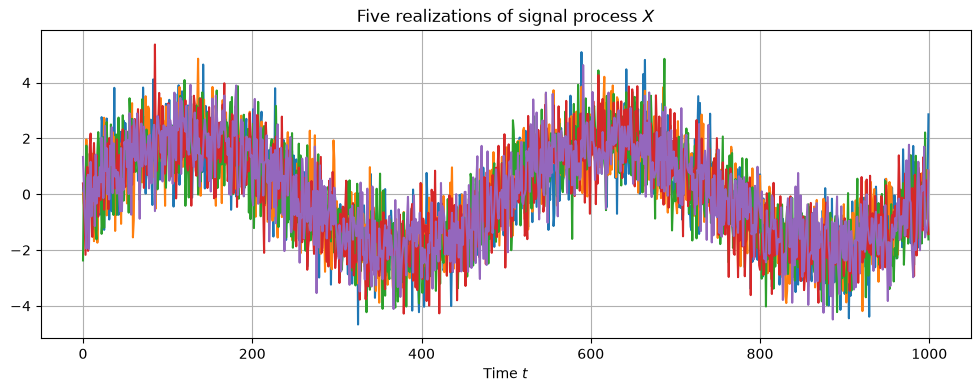

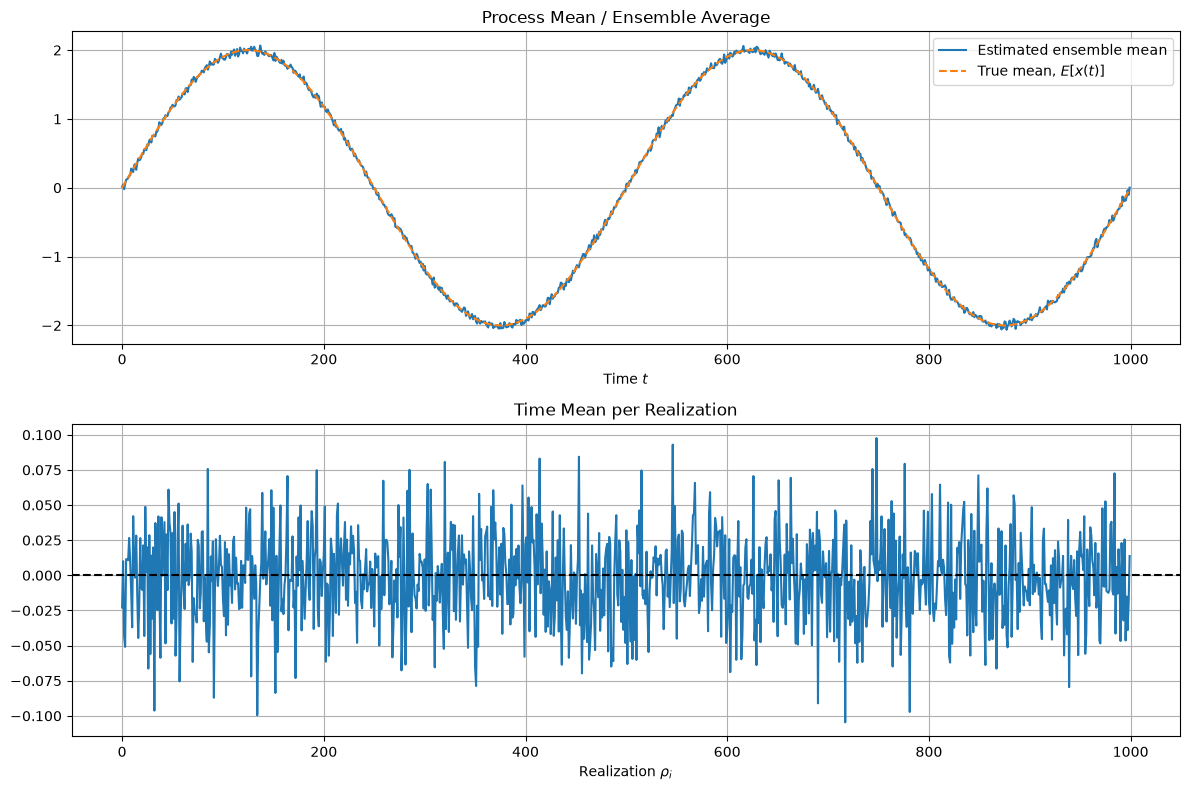

In [23]:
N = 1000
K = 1000
t = np.arange(N)

mean_signal = 2 * np.sin(2 * np.pi * 0.002 * t)
mean_signal = mean_signal.reshape(-1, 1) # convert signal from a (1000,) array to a (1000, 1) column
noise = rng.normal(size=(N, K)) 

X = mean_signal + noise

eta_t = X.mean(axis=1)
eta_rho = X.mean(axis=0)

plt.figure(figsize=(12, 4))
plt.plot(t, X[:, :5])
plt.xlabel("Time $t$")
plt.title("Five realizations of signal process $X$")
plt.grid(True)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(t, eta_t, label="Estimated ensemble mean")
axes[0].plot(t, mean_signal, "--", label="True mean, $E[x(t)]$")
axes[0].set_xlabel("Time $t$")
axes[0].set_title("Process Mean / Ensemble Average")
axes[0].legend()
axes[0].grid(True)

k = np.arange(K)
axes[1].plot(k, eta_rho)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel(r"Realization $\rho_i$")
axes[1].set_title("Time Mean per Realization")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Reflection and Academic Integrity Declaration

## Approach Summary
*In 3-5 sentences, describe what you did and why, in your own words, as if explaining it to a classmate who has not seen this exercise.*

In this machine exercise, I generated and analyzed discrete-time signals to examine their properties (symmetry, system behavior, frequency content). I've translated block diagrams and input signal graphs into code, then ran simulations to verify if the theoretical computations are reflected in practice. Lastly, I used computations and simulations to examine how random processes can be stationary or ergodic.

## Key Insight
*What is one result or observation from this exercise that surprised you, or didn’t match your initial intuition?*

I was surprised by how strongly the number of Fourier coefficients affects the accuracy of a reconstructed signal. I initially expected that many more coefficients would be necessary, but using around 100 coefficients already produced a good reconstruction of the input signal.

## Most Difficult Part
*What part of this exercise took the longest to get right, and how did you resolve it?*

I took the longest time working on the Random processes section since I tried to present my answer on whether the signal is stationary or not, and ergodic or not, by showing some computations. The complementary notes mostly described the graph and from there determine if it's stationary or ergodic. In the end I just computed for the expectation and from there, confirm if the signal is stationary or ergodic.

## Disclosure on the use of AI systems

| Section/Task | Tool Used | What you asked it for | Explain the result in your own words, as if teaching it |
| -------- | -------- | -------- | -------- |
| Plot Enhancements | Codex | Improve charts to make them clearer and more informative | Codex helped implement my planned chart presentation. For example, it helped create layered plots, such as the one-sided DFT with markers at the expected frequencies, so I could compare the theoretical and measured frequency components more clearly. |
| Research and Reference Lookup | Codex | Locate relevant material in the provided PDFs and documentation | I used Codex to search the provided course notes and documents more efficiently. It also helped identify Python equivalents for MATLAB functions mentioned in the exercise and complementary notes, and locate relevant library documentation. I used these references to understand and implement the work myself. |
| Markdown and LaTeX Formatting | Codex | Format Markdown content and construct LaTeX expressions | Because I had not used LaTeX recently, Codex helped convert my handwritten formulas into valid LaTeX and improve the notebook’s Markdown formatting. I reviewed the resulting formulas and formatting before including them in the notebook. |


## Self-Assessed Understanding
*For each objective or major problem in this exercise, rate your confidence (Confident / Mostly
confident / Still shaky) and add one sentence why.*

| Objective/problem | Confidence | Why |
| --- | --- | --- |
| 1.1 Signal Generation | Confident | I can generate discrete-time signals and use even-odd decomposition to verify their properties. |
| 1.2 Discrete-Time System Representations | Mostly confident | I can derive transfer functions and compare system representations, but I would benefit from more practice interpreting poles and stability. |
| 1.3 | N/A | This section is not included in the current notebook. |
| 1.4 Signal Synthesis Using Fourier Analysis | Mostly confident | I can compute Fourier coefficients and reconstruct a signal, and I understand how the number of coefficients affects reconstruction quality. |
| 1.5 Frequency Analysis of Signals | Mostly confident | I can use a one-sided DFT to identify frequency components and explain how frequency resolution affects peak error. |
| 1.6 Random Process | Mostly confident | I can calculate and compare ensemble and time averages, though I would like to further strengthen my understanding of stationarity and ergodicity. |


## Academic Honor Pledge

By submitting this exercise, I hereby affirm upon my honor the following:
1. The analysis, results, codes, answers to questions, discussions and conclusions in this machine exercise reflect my own understanding and work.
2. I used my own official student number whenever it is required, and the results generated were computed from my own personalized parameters/data, and not from anyone else.
3. I have disclosed fully and accurately any use of AI tools, LLMs, AI agents or similar systems in Section 4 above, and I can explain, in my own words, every part of what I submitted if asked.
4. I understand that submitting AI-generated work as my own can be considered as plagiarism and is an academic dishonesty, and that I abide with the University’s policy on Academic Integrity as written in the Student’s Code of Conduct.